<a href="https://colab.research.google.com/github/K-Sanyam-130/BIS_LAB/blob/main/LAB_3_ACO.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

EVENT: Sudden Traffic Spike on Link B -> D (Delay: 5ms -> 85ms, Packet Loss: 1% -> 35%)

METRIC                    | TRADITIONAL     | ACO OPTIMIZED  
Selected Route            | A->B->D         | A->B->C->D     
Avg End-to-End Latency    | 90.0 ms         | 19.0 ms        
Packet Delivery Ratio     | 67.2%           | 96.2%          
RESULT: Reduced Latency by 78.9% and improved Packet Delivery by +29.0%!

Graph saved successfully as 'aco_routing_optimization.png'


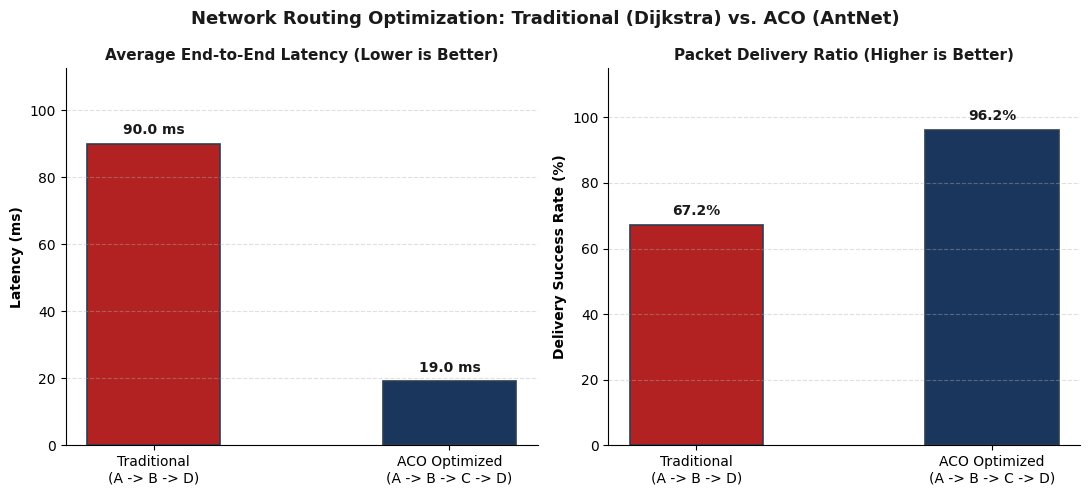

In [2]:
import heapq
import random
import matplotlib.pyplot as plt

# ==========================================
# 1. TRADITIONAL ROUTING (Static Dijkstra)
# ==========================================
def dijkstra_static_route(graph, source, destination):
    """Calculates the fixed shortest path once (ignores live traffic spikes)."""
    queue = [(0, source, [source])]
    visited = set()

    while queue:
        cost, node, path = heapq.heappop(queue)
        if node == destination:
            return path
        if node in visited:
            continue
        visited.add(node)

        for neighbor, metrics in graph[node].items():
            if neighbor not in visited:
                heapq.heappush(queue, (cost + metrics["delay"], neighbor, path + [neighbor]))
    return []


# ==========================================
# 2. ACO OPTIMIZED ROUTING (Dynamic AntNet)
# ==========================================
class ACONetworkRouter:
    def __init__(self, graph, alpha=1.0, beta=2.5, evaporation_rate=0.2, Q=100.0):
        self.graph = graph
        self.alpha = alpha
        self.beta = beta
        self.evap = evaporation_rate
        self.Q = Q
        self.pheromones = {
            u: {v: 1.0 / len(neighbors) for v in neighbors}
            for u, neighbors in graph.items()
        }

    def select_next_router(self, current, valid_neighbors):
        scores = {}
        total_score = 0.0
        for neighbor in valid_neighbors:
            tau = self.pheromones[current][neighbor] ** self.alpha
            delay = self.graph[current][neighbor]["delay"]
            eta = (1.0 / delay) ** self.beta
            score = tau * eta
            scores[neighbor] = score
            total_score += score

        pick = random.uniform(0, total_score)
        cumulative = 0.0
        for neighbor, score in scores.items():
            cumulative += score
            if cumulative >= pick:
                return neighbor
        return valid_neighbors[-1]

    def run_ants(self, source, destination, num_ants=15):
        for _ in range(num_ants):
            current = source
            visited = [source]
            total_delay = 0.0

            while current != destination:
                valid = [n for n in self.graph[current] if n not in visited]
                if not valid:
                    break
                nxt = self.select_next_router(current, valid)
                total_delay += self.graph[current][nxt]["delay"]
                visited.append(nxt)
                current = nxt

            if current == destination:
                deposit = self.Q / total_delay
                for i in range(len(visited) - 1, 0, -1):
                    curr_n, prev_n = visited[i], visited[i - 1]
                    for nb in self.pheromones[prev_n]:
                        self.pheromones[prev_n][nb] = max(
                            self.pheromones[prev_n][nb] * (1.0 - self.evap), 0.01
                        )
                    self.pheromones[prev_n][curr_n] += deposit

    def get_best_route(self, source, destination):
        current = source
        path = [current]
        while current != destination and len(path) <= len(self.graph):
            nxt = max(self.pheromones[current], key=self.pheromones[current].get)
            path.append(nxt)
            current = nxt
        return path


# ==========================================
# 3. PERFORMANCE EVALUATOR (Measures Gains)
# ==========================================
def simulate_traffic(graph, path, total_packets=500):
    """Sends packets along a path and measures Latency & Packet Delivery Ratio."""
    total_delay = 0.0
    dropped_packets = 0

    for _ in range(total_packets):
        packet_dropped = False
        packet_delay = 0.0

        for i in range(len(path) - 1):
            u, v = path[i], path[i + 1]
            link = graph[u][v]
            packet_delay += link["delay"]

            if random.random() < link["loss_rate"]:
                packet_dropped = True
                break

        if packet_dropped:
            dropped_packets += 1
        else:
            total_delay += packet_delay

    delivered = total_packets - dropped_packets
    avg_latency = (total_delay / delivered) if delivered > 0 else float("inf")
    delivery_ratio = (delivered / total_packets) * 100
    return avg_latency, delivery_ratio


# ==========================================
# 4. GRAPH GENERATOR (Formal Navy Blue & Crimson Red)
# ==========================================
def plot_optimization_results(trad_latency, aco_latency, trad_pdr, aco_pdr, static_path, aco_path):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 5))
    fig.suptitle(
        "Network Routing Optimization: Traditional (Dijkstra) vs. ACO (AntNet)",
        fontsize=13,
        fontweight="bold",
        color="#1a1a1a",
        y=0.98
    )

    methods = [
        f"Traditional\n({' -> '.join(static_path)})",
        f"ACO Optimized\n({' -> '.join(aco_path)})"
    ]
    # Formal colors: Crimson Red for Traditional, Navy Blue for ACO Optimized
    colors = ["#B22222", "#1B365D"]

    # --- Subplot 1: Average End-to-End Latency (Lower is Better) ---
    bars1 = ax1.bar(methods, [trad_latency, aco_latency], color=colors, width=0.45, edgecolor="#2c3e50", linewidth=1.2)
    ax1.set_title("Average End-to-End Latency (Lower is Better)", fontsize=11, fontweight="bold", color="#1a1a1a")
    ax1.set_ylabel("Latency (ms)", fontsize=10, fontweight="bold")
    ax1.set_ylim(0, max(trad_latency, aco_latency) * 1.25)
    ax1.grid(axis="y", linestyle="--", alpha=0.4)
    ax1.spines["top"].set_visible(False)
    ax1.spines["right"].set_visible(False)

    for bar in bars1:
        yval = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width() / 2, yval + 2, f"{yval:.1f} ms",
                 ha="center", va="bottom", fontweight="bold", fontsize=10, color="#1a1a1a")

    # --- Subplot 2: Packet Delivery Ratio (Higher is Better) ---
    bars2 = ax2.bar(methods, [trad_pdr, aco_pdr], color=colors, width=0.45, edgecolor="#2c3e50", linewidth=1.2)
    ax2.set_title("Packet Delivery Ratio (Higher is Better)", fontsize=11, fontweight="bold", color="#1a1a1a")
    ax2.set_ylabel("Delivery Success Rate (%)", fontsize=10, fontweight="bold")
    ax2.set_ylim(0, 115)
    ax2.grid(axis="y", linestyle="--", alpha=0.4)
    ax2.spines["top"].set_visible(False)
    ax2.spines["right"].set_visible(False)

    for bar in bars2:
        yval = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width() / 2, yval + 2, f"{yval:.1f}%",
                 ha="center", va="bottom", fontweight="bold", fontsize=10, color="#1a1a1a")

    plt.tight_layout()
    plt.savefig("aco_routing_optimization.png", dpi=300)
    print("\nGraph saved successfully as 'aco_routing_optimization.png'")
    plt.show()


# ==========================================
# MAIN DEMO: PROOF OF OPTIMIZATION
# ==========================================
if __name__ == "__main__":
    random.seed(42)

    network = {
        "A": {"B": {"delay": 5, "loss_rate": 0.01}, "C": {"delay": 10, "loss_rate": 0.01}},
        "B": {"A": {"delay": 5, "loss_rate": 0.01}, "D": {"delay": 5, "loss_rate": 0.01}, "C": {"delay": 4, "loss_rate": 0.01}},
        "C": {"A": {"delay": 10, "loss_rate": 0.01}, "D": {"delay": 10, "loss_rate": 0.01}, "B": {"delay": 4, "loss_rate": 0.01}},
        "D": {"B": {"delay": 5, "loss_rate": 0.01}, "C": {"delay": 10, "loss_rate": 0.01}},
    }

    # 1. Traditional routing locks onto A -> B -> D
    static_path = dijkstra_static_route(network, "A", "D")

    # 2. ACO trains on initial network
    aco = ACONetworkRouter(network)
    for _ in range(20):
        aco.run_ants("A", "D")

    # 3. Sudden network congestion on B -> D
    print("EVENT: Sudden Traffic Spike on Link B -> D (Delay: 5ms -> 85ms, Packet Loss: 1% -> 35%)\n")
    network["B"]["D"]["delay"] = 85
    network["B"]["D"]["loss_rate"] = 0.35

    # ACO adapts to the live traffic jam
    for _ in range(20):
        aco.run_ants("A", "D")
    aco_path = aco.get_best_route("A", "D")

    # 4. Simulate 500 packets and print terminal table
    trad_latency, trad_pdr = simulate_traffic(network, static_path, total_packets=500)
    aco_latency, aco_pdr = simulate_traffic(network, aco_path, total_packets=500)

    latency_improvement = ((trad_latency - aco_latency) / trad_latency) * 100
    pdr_improvement = aco_pdr - trad_pdr

    print("=" * 62)
    print(f"{'METRIC':<25} | {'TRADITIONAL':<15} | {'ACO OPTIMIZED':<15}")
    print("=" * 62)
    print(f"{'Selected Route':<25} | {'->'.join(static_path):<15} | {'->'.join(aco_path):<15}")
    print(f"{'Avg End-to-End Latency':<25} | {f'{trad_latency:.1f} ms':<15} | {f'{aco_latency:.1f} ms':<15}")
    print(f"{'Packet Delivery Ratio':<25} | {f'{trad_pdr:.1f}%':<15} | {f'{aco_pdr:.1f}%':<15}")
    print("=" * 62)
    print(f"RESULT: Reduced Latency by {latency_improvement:.1f}% and improved Packet Delivery by +{pdr_improvement:.1f}%!")

    # 5. Display and save the comparison graph
    plot_optimization_results(trad_latency, aco_latency, trad_pdr, aco_pdr, static_path, aco_path)
